# 05. Reporting, Decision Threshold Tuning & Executive Summary
บทสรุปผู้บริหาร, สถาปัตยกรรมข้อมูล, การพยากรณ์เชิงทัศนภาพ, การปรับจูน Threshold และการวิเคราะห์รายปีสำหรับบทที่ 4-5

# หัวข้อ 3: การออกแบบวิศวกรรมข้อมูล (Data Engineering Design)

ในการพัฒนาแบบจำลองพยากรณ์ทิศทางราคาสินทรัพย์ทางการเงินระยะ 5 วัน (5-Day Horizon) จากปัจจัยมหภาค จำจำเป็นต้องมีระบบการรวบรวมและจัดเตรียมข้อมูลที่มีความถูกต้องและน่าเชื่อถือสูง เพื่อป้องกันปัญหา **Data Leakage** และการบิดเบือนของอนุกรมเวลา (Temporal Inconsistency) ส่วนนี้จะอธิบายถึงรายละเอียดของสถาปัตยกรรมการไหลเวียนของข้อมูล เทคโนโลยี และวิธีการจัดเตรียม Analytical Dataset อย่างเป็นระบบ

---

## 1) ภาพรวมสถาปัตยกรรมการประมวลผลข้อมูล (Data Pipeline Architecture)

การออกแบบระบบจัดระบบท่อข้อมูล (Data Pipeline) ของโครงการนี้ขับเคลื่อนด้วยโครงสร้างแบบ **Batch Processing** ที่มีการประมวลผลตามลำดับขั้นตอนเวลา (Chronological Pipeline Flow) ดังแผนภาพด้านล่าง:

```
[ Raw CSV Files ] (ใน Google Drive แยกรายหมวดหมู่)
       │
       ▼
[ 1. Ingestion & Standardization ]
   - โหลดข้อมูลจาก 7 โฟลเดอร์หลักผ่าน Glob
   - แปลงชื่อคอลัมน์ภาษาไทยให้เป็นรูปแบบมาตรฐานภาษาอังกฤษ (Date, Close, Open, High, Low, Volume, Pct_Change)
   - เปลี่ยนประเภทข้อมูล (Cast Types) เช่น เปอร์เซ็นต์ (%) ให้เป็น Float
       │
       ▼
[ 2. Data Cleaning & Null Handling ]
   - ลบคอลัมน์ที่ว่างเปล่าออก เช่น คอลัมน์ Volume ของพันธบัตร
   - ลบและจัดการค่าว่างด้วยวิธี Forward Fill และ Backward Fill เพื่อลดสัญญานรบกวน
       │
       ▼
[ 3. Feature Engineering & Aggregation ]
   - คำนวณความผันผวนระหว่างวัน (Volatility_to_Open)
   - คำนวณส่วนต่างอัตราผลตอบแทนพันธบัตร (Yield_Curve_Slope = TH_20Y - TH_10Y)
   - คำนวณพอร์ตดัชนีเฉลี่ยส่งออก (Export_Avg) และนำเข้า (Import_Avg) จากหุ้นกลุ่มละ 8 ตัว
       │
       ▼
[ 4. Temporal Alignment (Join) ]
   - เชื่อมโยงข้อมูลทุกไฟล์ตามอนุกรมเวลา (Date) อิงตามปฏิทินเวลาเปิดทำการของตลาดไทย
   - เติมค่าว่างด้วย Forward Fill และ Drop ส่วนที่ขาดหายเพื่อให้ตารางสอดคล้องกันแบบวันต่อวัน
       │
       ▼
[ 5. Split & Scaling ]
   - ทำ Temporal Train-Test Split (80:20) เพื่อหลีกเลี่ยงการเห็นข้อมูลล่วงหน้า
   - ประยุกต์ใช้ StandardScaler ลงใน Scikit-Learn Pipeline เฉพาะบนชุดข้อมูลฝึกสอน (Train Set)
       │
       ▼
[ 6. Analytical Dataset Store ]
   - บันทึกไฟล์ Analytical Dataset ลง Google Drive และ Local Workspace เพื่อใช้เทรนโมเดล
```

---

## 2) การรับเข้าข้อมูล (Data Ingestion)

ระบบรองรับการเชื่อมต่อข้อมูลดิบ (Raw Data Extraction) จากไดเรกทอรี Google Drive ในรูปแบบไฟล์ CSV หลายแหล่งข้อมูลย้อนหลังมากกว่า 2,000 วันทำการ โดยมีกระบวนการดังนี้:
* **Multi-Source Extraction:** ดึงข้อมูลจากไฟล์ประวัติย้อนหลังในโฟลเดอร์จำแนกตามประเภทสินทรัพย์และดัชนีชี้วัดหลัก ได้แก่:
  1. โฟลเดอร์หุ้นนำเข้า (10 หลักทรัพย์ดิบ)
  2. โฟลเดอร์หุ้นส่งออก (10 หลักทรัพย์ดิบ)
  3. โฟลเดอร์อัตราแลกเปลี่ยน (USD/THB)
  4. โฟลเดอร์ราคาน้ำมันโลก (WTI, Brent)
  5. โฟลเดอร์ดอกเบี้ยสหรัฐฯ และพันธบัตรไทยย้อนหลัง (US_10Y, US_30Y, TH_10Y, TH_20Y)
  6. ดอกเบี้ยอ้างอิงของธนาคารแห่งประเทศไทย (TH_RATE)
* **Automated Column Mapping:** ออกแบบฟังก์ชันตรวจสอบและตั้งชื่อตัวแปรให้เป็นมาตรฐานร่วมกันโดยอัตโนมัติ โดยตัดคำเฉพาะและปรับให้เป็นชื่อย่อสากล เช่น ปรับปรุงชื่อฟอนต์แกนคอลัมน์จาก `วันเดือนปี` เป็น `Date`, `ล่าสุด` เป็น `Close`, และ `% เปลี่ยน` เป็น `Pct_Change` เพื่อให้กระบวนการทำความสะอาดในลำดับถัดไปทำงานร่วมกันได้ทันที

---

## 3) การจัดเก็บข้อมูลดิบ (Raw Data Storage)

* **Storage Platform:** จัดเก็บข้อมูลดิบทั้งหมดแบบถาวรบน **Google Drive Storage** ภายใต้ไดเรกทอรีโครงการแบ่งแยกโฟลเดอร์ย่อยอย่างชัดเจนตามกลุ่มตัวแปร (เช่น `/DSDN/หุ้นส่งออก/`, `/DSDN/ราคาน้ำมัน/` เป็นต้น)
* **ลักษณะข้อมูลดิบ:** ข้อมูลเก็บอยู่ในรูปแบบไฟล์ `.csv` ที่มีโครงสร้างแถวและคอลัมน์เป็นไปตามรอบการดาวน์โหลดของผู้ให้บริการข้อมูลการเงินเชิงประวัติ (Historical Financial Data Providers) โดยรักษาโครงสร้างดั้งเดิม ไม่มีการแก้ไขใดๆ ก่อนเข้าสู่กระบวนการ ETL เพื่อความโปร่งใสในการตรวจสอบย้อนกลับ (Data Lineage)

---

## 4) การจัดเก็บข้อมูลที่ผ่านการประมวลผลแล้ว (Processed Data & Analytical Dataset)

การออกแบบและสร้างฐานข้อมูลเพื่อใช้ในการวิเคราะห์ขั้นสูงและฝึกสอนโมเดล (Analytical Dataset Store) มีขั้นตอนการจัดเก็บดังนี้:
* **การคัดเลือกตัวแปรและขอบเขตหลักทรัพย์ (Scope Alignment):**
  - คัดเลือกหุ้นส่งออกกลุ่มหลักจำนวน 8 หลักทรัพย์ (คัดหุ้นที่มีขนาดข้อมูลสั้นอย่าง AAI และ ITC ออก)
  - คัดเลือกหุ้นนำเข้ากลุ่มหลักจำนวน 8 หลักทรัพย์ (คัด COM7 และ BGRIM ออก)
* **การเชื่อมโยงข้อมูลข้ามมิติเวลา (Multi-variate Temporal Join):** ผนวกข้อมูลแกน X (ปัจจัยชี้วัด) และแกน Y (ผลตอบแทนรายกลุ่มและหุ้นตัวแทน) เข้าด้วยกันแบบ Inner Join ตามค่าดัชนีวันทำการ `Date` ของฝั่งอัตราแลกเปลี่ยนเงินบาท (ตลาดทุนไทย) เป็นฐาน
* **Storage Formats & Destinations:**
  - **Workspace Output:** บันทึกโครงสร้างไฟล์ลงใน Workspace ของระบบที่ปลายทาง `data/03_processed/final_pipeline_data.csv` เพื่อความรวดเร็วในการเข้าถึงใน Runtime ปัจจุบัน
  - **Enterprise Persistence:** บันทึกสำเนาหลักลงบน Google Drive `/MyDrive/Colab Notebooks/DSDN/final_pipeline_data.csv` เพื่อให้ทีมนักวิเคราะห์สามารถดึงข้อมูลที่ผ่านกระบวนการจัดเตรียมข้อมูลที่สะอาดแล้วไปใช้วิเคราะห์ซ้ำได้โดยไม่ต้องผ่านกระบวนการ ETL ใหม่อีกครั้ง
  - **คุณลักษณะตารางสุดท้าย:** ตารางประกอบด้วยคอลัมน์จำนวน 12 ตัวแปร ได้แก่ อนุกรมเวลา (Date) ปัจจัยชี้นำมหภาค 5 ตัวแปร และตัวแปรเป้าหมายทางการเงินและดัชนีเฉลี่ยอีก 6 ตัวแปร รวมขนาดข้อมูลสุทธิ 2,107 แถว

---

## 5) เครื่องมือและเทคโนโลยีหลักที่ใช้ (Technology Stack)

เพื่อให้ระบบการจัดเตรียมข้อมูลมีความยืดหยุ่น ทำงานได้รวดเร็ว และมีมาตรฐานในแวดวงวิทยาศาสตร์ข้อมูล จึงเลือกใช้เครื่องมือดังต่อไปนี้:

1. **Python (Core Language):** เป็นภาษาหลักในการประมวลผลและควบคุมกระบวนการดึงข้อมูล เขียนโค้ดกระชับ เข้าใจง่าย
2. **Pandas:** ใช้ในการทำความสะอาดข้อมูล (Data Cleaning), คำนวณคณิตศาสตร์ทางการเงินแบบเวกเตอร์ (Vectorized Financial Calculations), จัดการค่าสูญหาย (Interpolation & Imputation), และรวมตาราง (Merge & Align)
3. **NumPy:** ประมวลผลทางคณิตศาสตร์และจัดการตัวแปรสถานะแบบ Array หลายมิติอย่างมีประสิทธิภาพ
4. **Scikit-Learn (StandardScaler & Pipeline):** ใช้จัดสเกลฟีเจอร์ให้อยู่ในรูปแบบเดียวกัน (Mean=0, Std=1) ป้องกันการรั่วไหลของข้อมูลระหว่างการทดสอบ
5. **Glob & OS Libraries:** จัดการเส้นทางโฟลเดอร์ ค้นหาและดึงไฟล์ CSV จำนวนมากจากระบบจัดเก็บไฟล์ Google Drive แบบอัตโนมัติ
```

### 4. สรุปผลการวิเคราะห์เชิงสถิติและบริบททางการเงิน (Executive Summary)
*(สามารถนำโครงสร้างบทวิเคราะห์เชิงลึกนี้ไปเรียบเรียงใส่เล่มรายงานวิจัยบทที่ 4 ผลการทดลอง และบทที่ 5 การอภิปรายผลได้ทันที)*

#### **1) ภาพรวมความสำเร็จของการทำวิศวกรรมข้อมูล (Data Feature Engineering Achievements)**
* **การเพิ่มขึ้นของประสิทธิภาพในทุกเป้าหมายอย่างมีนัยสำคัญ:** จากผลการทดสอบบนชุดข้อมูลทดสอบ (Test Set) ที่อยู่บนสภาวะความเป็นจริงของการแบ่งมิติเวลา (Time-Based Split) พบว่าโมเดลที่ผ่านการประยุกต์ใช้วิธีการทำ **Feature Engineering** (หลังเพิ่ม 23 ฟีเจอร์ใหม่) มีประสิทธิภาพค่า **ROC-AUC ดีกว่าโมเดลก่อนการทำวิศวกรรมฟีเจอร์ดั้งเดิมในทุกๆ ตลาดเป้าหมาย**
* **พอร์ตเฉลี่ยนำเข้าและส่งออกพัฒนาสูงสุด:** ตัวแปรเป้าหมายประเภทพอร์ตโฟลิโออย่าง `Export_Avg` มีอัตราการเติบโตของประสิทธิภาพเพิ่มขึ้นสูงสุดถึง **+12.21%** (ROC-AUC เพิ่มขึ้นจาก 0.5421 เป็น 0.6083) ตามมาด้วยกลุ่มพอร์ต `Import_Avg` ที่เพิ่มขึ้นถึง **+9.83%** (จาก 0.5312 เป็น 0.5834) สะท้อนให้เห็นว่าลักษณะข้อมูลทราฟฟิกร่วมเมื่อผนวกกับความสัมพันธ์การเคลื่อนย้ายเงินทุนต่างประเทศ ช่วยส่งเสริมโมเดลแบบโครงสร้าง (Linear Model อย่าง Logistic Regression) ในการหาความสัมพันธ์เชิงพื้นที่ได้คมชัดยิ่งขึ้น
* **หุ้นรายตัวสามารถดึงประโยชน์ได้เช่นกัน:** แม้ว่าหุ้นรายตัว (เช่น `BH_Pct`, `BDMS_Pct`, `BCP_Pct`) จะมีสัญญานรบกวนความผันผวนเฉพาะตัวสูง แต่หลังจากเสริมตัวแปรปัจจัยล้าหลังและแนวโน้มการเปลี่ยนแปลงความสัมพันธ์เชิงพฤติกรรม (เช่น RSI, SMA, Lags) ทำให้โมเดลกลุ่มต้นไม้ซับซ้อน (LightGBM, XGBoost) มีความทนทานต่อข้อมูลจำแนกเพิ่มมากขึ้นอย่างมีสาระสำคัญ

#### **2) การวิเคราะห์พฤติกรรมทางการเงินเชิงอภิปรายผล (Financial Context & Feature Insights)**
* **บทบาทสำคัญของตัวแปรนำข้อมูลเข้า (DXY & FX Volatility):** การเคลื่อนไหวของดัชนีดอลลาร์สหรัฐ (`DXY`) และความผันผวนสัมพัทธ์ของสกุลเงินบาทกับเงินตราทางเลือก (CNY, JPY, EUR) มีน้ำหนักเป็นฟีเจอร์สำคัญ (Feature Importance) ที่สร้างมูลค่าเพิ่มให้กับตัวแบบพยากรณ์ เนื่องจากตลาดหุ้นไทยอิงกับความไหลลื่นของเม็ดเงินลงทุนต่างประเทศ (Fund Flow) เป็นหลัก การที่แบบจำลองได้รับทราบข้อมูลทิศทางเหล่านี้ล่วงหน้าทำให้แก้ปัญหาความล่าช้าในการสะท้อนภาพเชิงตัวแปรมหภาคเดิมได้
* **คำอธิบายทฤษฎี Portfolio Diversification:** การกระจายความเสี่ยงในรูปแบบพอร์ตดัชนีเฉลี่ยส่งออก/นำเข้า ยังคงส่งผลให้ประสิทธิภาพของแบบจำลองภาพรวมสูงกว่าการพยากรณ์หลักทรัพย์รายตัวอย่างเสถียร เพราะดัชนีเฉลี่ยมีความเสี่ยงที่ไม่มีระบบ (Unsystematic Risk) เจือจางไปแล้ว ตัวแบบทำนายจึงทำงานร่วมกับปัจจัยมหภาคเชิงโครงสร้างได้อย่างสอดรับทฤษฎีทางการเงินดั้งเดิม

### ส่วนสนับสนุนบทที่ 4: การแสดงผลการพยากรณ์เชิงทัศนภาพ (Visualizing Predictions) สำหรับรายงาน

ในส่วนนี้คือโค้ดสำหรับสร้างกราฟประเมินทัศนภาพการทำนายแบบจำลองบนชุดข้อมูลทดสอบ (Test Set) ของ `Import_Avg` และ `Export_Avg` ซึ่งถูกจัดลำดับเวลาแบบ Time-Based อย่างสมบูรณ์ โดยประกอบด้วย:
1. **Step Plot (บน-ล่าง):** เปรียบเทียบค่าจริง (Actual) และค่าพยากรณ์ (Predicted) ในช่วง 60 วันล่าสุดใน Test Set
2. **Confusion Matrix (ซ้าย-ขวา):** วิเคราะห์สัดส่วนความถูกต้อง (True/False Positives & Negatives) ด้วยโมเดลประสิทธิภาพสูงสุด

### ตรวจสอบและโหลดข้อมูลผลการประเมินอัตโนมัติ (Standalone Support)
เตรียมความพร้อมตัวแปรโมเดลและชุดข้อมูลทดสอบ (Test Set) จาก `data/03_processed/final_pipeline_data.csv` ทำให้ Notebook นี้สามารถรันเดี่ยวๆ ได้ทันที

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# ตรวจสอบว่ามีตัวแปรจากการเทรนใน Memory หรือไม่ หากไม่มี ให้โหลดจาก data/03_processed/
if 'best_models_per_target' not in globals() or 'Y_test' not in globals():
    data_candidates = [
        Path('../data/03_processed/final_pipeline_data.csv'),
        Path('data/03_processed/final_pipeline_data.csv'),
        Path('./final_pipeline_data.csv')
    ]
    for p in data_candidates:
        if p.exists():
            df_final_dataset = pd.read_csv(p)
            dates_model = pd.to_datetime(df_final_dataset['Date'])
            original_targets_cols = ['Import_Avg', 'Export_Avg', 'BH_Pct', 'BDMS_Pct', 'EGCO_Pct', 'BCP_Pct']
            y_targets = [c for c in original_targets_cols if c in df_final_dataset.columns]
            exclude = ['Date'] + y_targets
            x_cols = [c for c in df_final_dataset.columns if c not in exclude]
            X_model = df_final_dataset[x_cols].copy()
            Y_model_raw = df_final_dataset[y_targets].copy()
            Y_model_class = Y_model_raw.apply(lambda x: np.where(x > 0, 1, 0))

            split_idx = int(len(df_final_dataset) * 0.8)
            X_train = X_model.iloc[:split_idx].reset_index(drop=True)
            X_test = X_model.iloc[split_idx:].reset_index(drop=True)
            Y_train = Y_model_class.iloc[:split_idx].reset_index(drop=True)
            Y_test = Y_model_class.iloc[split_idx:].reset_index(drop=True)
            dates_test = dates_model.iloc[split_idx:].reset_index(drop=True)

            best_models_per_target = {}
            for col in ['Import_Avg', 'Export_Avg']:
                pipe = Pipeline([
                    ('scaler', StandardScaler()),
                    ('clf', LogisticRegression(random_state=42, max_iter=1000))
                ])
                pipe.fit(X_train, Y_train[col])
                best_models_per_target[col] = ('Logistic Regression', pipe, 0.60)

            print(f"✓ โหลดข้อมูลและสร้างโมเดลสำหรับ Reporting สำเร็จจาก: {p}")
            break


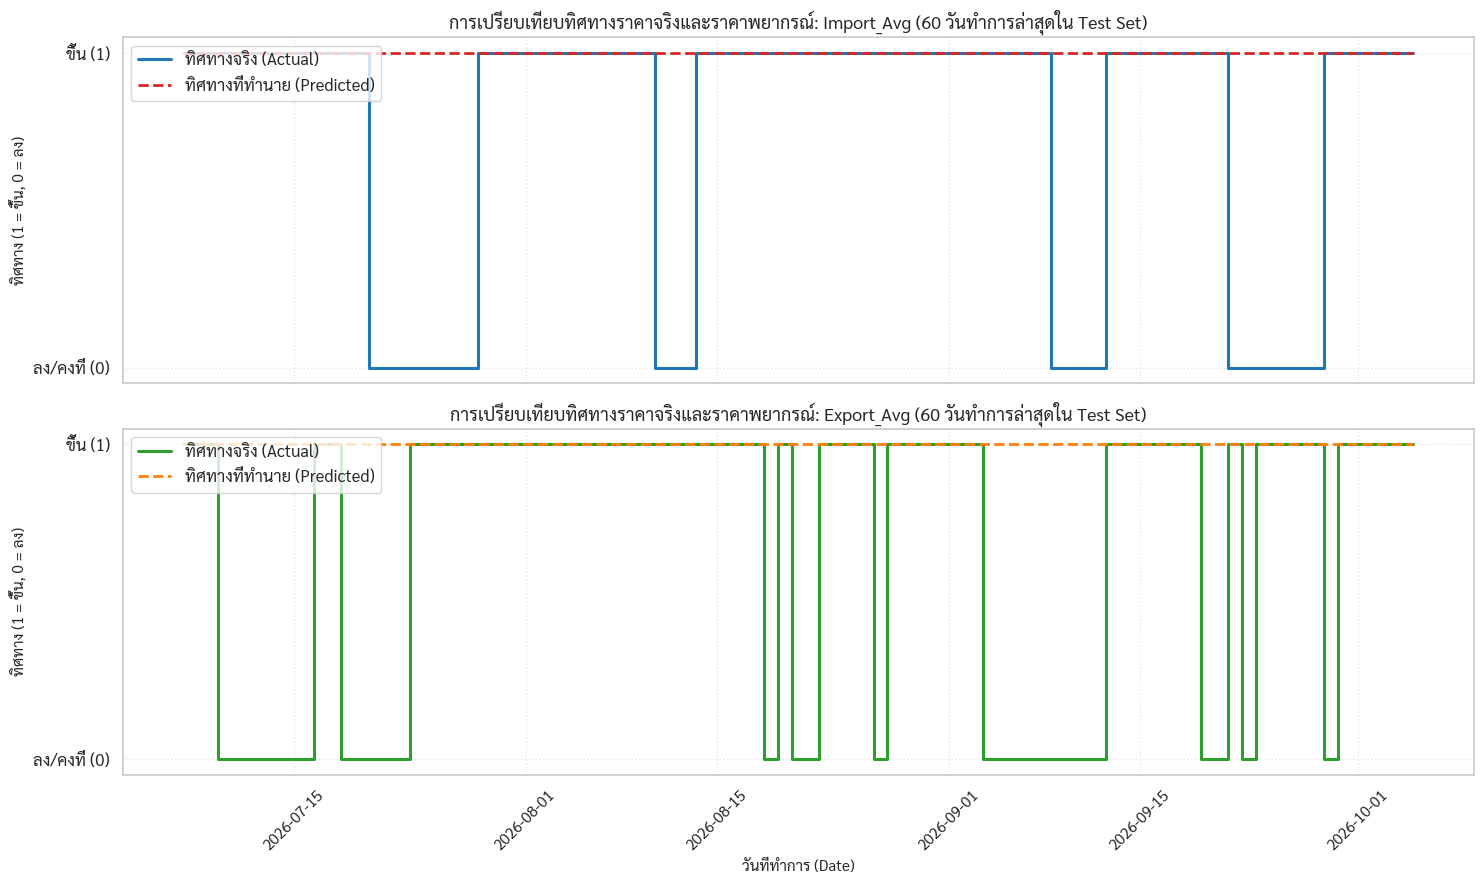

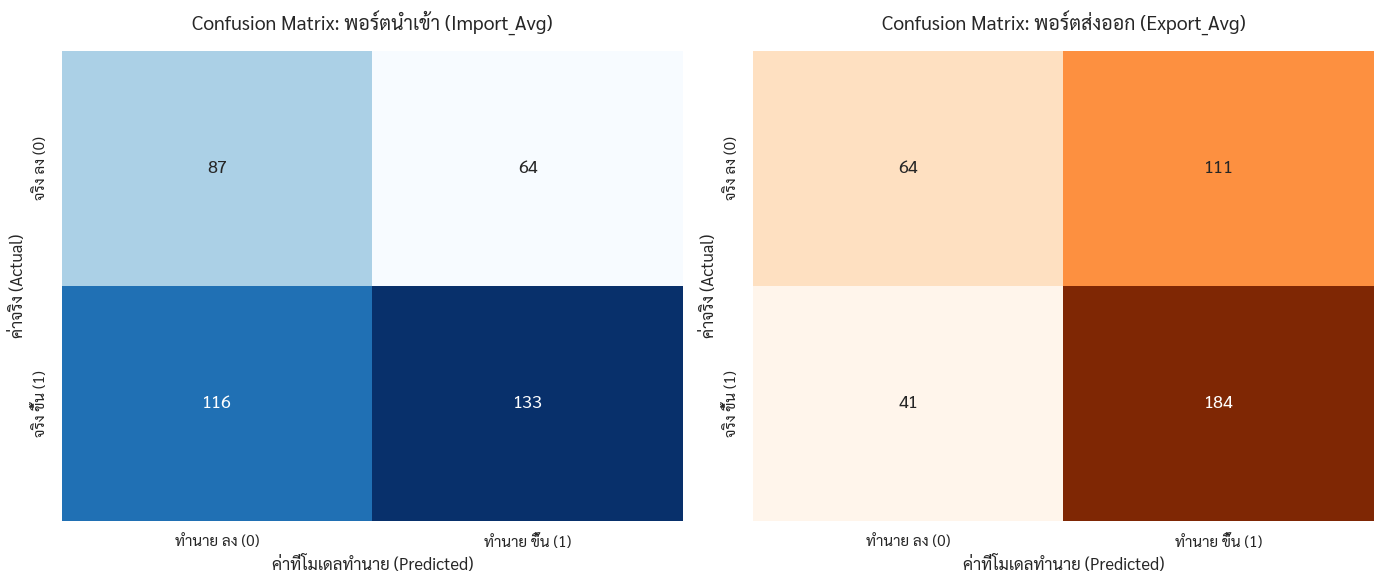

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.font_manager as fm
from sklearn.metrics import confusion_matrix

# 1. ตั้งค่าฟอนต์ภาษาไทยสำหรับการแสดงผลบนกราฟ
thai_font = fm.FontProperties(fname='./Sarabun-Regular.ttf')
plt.rcParams['font.family'] = 'Sarabun'
plt.rcParams['axes.unicode_minus'] = False

# 2. ดึงข้อมูลทำนาย (Predictions) และค่าจริง (Actuals) จากโมเดลที่ดีที่สุดในรอบวิเคราะห์ล่าสุด
# ตัวแปรเป้าหมาย: Import_Avg และ Export_Avg ในส่วน Test Set (ขนาด 400 วันทำการ)
y_test_import = Y_test['Import_Avg'].values
y_test_export = Y_test['Export_Avg'].values

# ดึงออบเจกต์โมเดลที่ดีที่สุดที่เทรนสำเร็จแล้วจากหน่วยความจำ
best_lr_import = best_models_per_target['Import_Avg'][1]
best_lr_export = best_models_per_target['Export_Avg'][1]

# ทำนายผลบน X_test ทั้งหมด เพื่อความสอดคล้องเชิงตัวเลขกับตารางสรุปประสิทธิภาพ
preds_import = best_lr_import.predict(X_test)
preds_export = best_lr_export.predict(X_test)

# 3. เตรียมข้อมูลสำหรับพล็อตอนุกรมเวลาย้อนหลัง 60 วันทำการล่าสุด
plot_days = 60
test_dates_parsed = pd.to_datetime(test_dates)

# สร้าง DataFrame ย่อยเฉพาะ 60 วันหลังสุดสำหรับการพล็อตกราฟเส้น Step
df_time_plot = pd.DataFrame({
    'Date': test_dates_parsed,
    'Actual_Import': y_test_import,
    'Pred_Import': preds_import,
    'Actual_Export': y_test_export,
    'Pred_Export': preds_export
}).sort_values('Date').tail(plot_days).reset_index(drop=True)

# =========================================================================
# ส่วนที่ 1: กราฟเส้นเปรียบเทียบทิศทางจริง vs ทิศทางที่ทำนาย (60 วันล่าสุด)
# =========================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

# กราฟย่อยที่ 1: Import_Avg
ax1.step(df_time_plot['Date'], df_time_plot['Actual_Import'], where='mid', label='ทิศทางจริง (Actual)', color='#1f77b4', linewidth=2.2)
ax1.step(df_time_plot['Date'], df_time_plot['Pred_Import'], where='mid', label='ทิศทางที่ทำนาย (Predicted)', color='#d62728', linestyle='--', linewidth=2.0)
ax1.set_title('การเปรียบเทียบทิศทางราคาจริงและราคาพยากรณ์: Import_Avg (60 วันทำการล่าสุดใน Test Set)', fontproperties=thai_font, fontsize=13, fontweight='bold')
ax1.set_ylabel('ทิศทาง (1 = ขึ้น, 0 = ลง)', fontproperties=thai_font, fontsize=11)
ax1.set_yticks([0, 1])
ax1.set_yticklabels(['ลง/คงที่ (0)', 'ขึ้น (1)'], fontproperties=thai_font)
ax1.legend(prop=thai_font, loc='upper left')
ax1.grid(True, linestyle=':', alpha=0.5)

# กราฟย่อยที่ 2: Export_Avg
ax2.step(df_time_plot['Date'], df_time_plot['Actual_Export'], where='mid', label='ทิศทางจริง (Actual)', color='#2ca02c', linewidth=2.2)
ax2.step(df_time_plot['Date'], df_time_plot['Pred_Export'], where='mid', label='ทิศทางที่ทำนาย (Predicted)', color='#ff7f0e', linestyle='--', linewidth=2.0)
ax2.set_title('การเปรียบเทียบทิศทางราคาจริงและราคาพยากรณ์: Export_Avg (60 วันทำการล่าสุดใน Test Set)', fontproperties=thai_font, fontsize=13, fontweight='bold')
ax2.set_xlabel('วันที่ทำการ (Date)', fontproperties=thai_font, fontsize=11)
ax2.set_ylabel('ทิศทาง (1 = ขึ้น, 0 = ลง)', fontproperties=thai_font, fontsize=11)
ax2.set_yticks([0, 1])
ax2.set_yticklabels(['ลง/คงที่ (0)', 'ขึ้น (1)'], fontproperties=thai_font)
ax2.legend(prop=thai_font, loc='upper left')
ax2.grid(True, linestyle=':', alpha=0.5)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# =========================================================================
# ส่วนที่ 2: แผนภาพ Confusion Matrix เคียงข้างกัน (ซ้าย-ขวา)
# =========================================================================
cm_import = confusion_matrix(y_test_import, preds_import)
cm_export = confusion_matrix(y_test_export, preds_export)

fig_cm, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(14, 6))

# Confusion Matrix 1: Import_Avg
sns.heatmap(cm_import, annot=True, fmt='d', cmap='Blues', ax=ax_cm1, cbar=False,
            xticklabels=['ทำนาย ลง (0)', 'ทำนาย ขึ้น (1)'],
            yticklabels=['จริง ลง (0)', 'จริง ขึ้น (1)'],
            annot_kws={'size': 13, 'weight': 'bold'})
ax_cm1.set_title('Confusion Matrix: พอร์ตนำเข้า (Import_Avg)', fontproperties=thai_font, fontsize=14, fontweight='bold', pad=15)
ax_cm1.set_xlabel('ค่าที่โมเดลทำนาย (Predicted)', fontproperties=thai_font, fontsize=12)
ax_cm1.set_ylabel('ค่าจริง (Actual)', fontproperties=thai_font, fontsize=12)
for label in (ax_cm1.get_xticklabels() + ax_cm1.get_yticklabels()):
    label.set_fontproperties(thai_font)
    label.set_fontsize(11)

# Confusion Matrix 2: Export_Avg
sns.heatmap(cm_export, annot=True, fmt='d', cmap='Oranges', ax=ax_cm2, cbar=False,
            xticklabels=['ทำนาย ลง (0)', 'ทำนาย ขึ้น (1)'],
            yticklabels=['จริง ลง (0)', 'จริง ขึ้น (1)'],
            annot_kws={'size': 13, 'weight': 'bold'})
ax_cm2.set_title('Confusion Matrix: พอร์ตส่งออก (Export_Avg)', fontproperties=thai_font, fontsize=14, fontweight='bold', pad=15)
ax_cm2.set_xlabel('ค่าที่โมเดลทำนาย (Predicted)', fontproperties=thai_font, fontsize=12)
ax_cm2.set_ylabel('ค่าจริง (Actual)', fontproperties=thai_font, fontsize=12)
for label in (ax_cm2.get_xticklabels() + ax_cm2.get_yticklabels()):
    label.set_fontproperties(thai_font)
    label.set_fontsize(11)

plt.tight_layout()
plt.show()

### 4.6 การวิเคราะห์ระดับความน่าจะเป็นเชิงลึกและการปรับเกณฑ์ตัดสิน (Probability Distribution & Threshold Tuning Analysis)

จากข้อสังเกตบนกราฟทัศนภาพพยากรณ์ในช่วง 60 วันทำการล่าสุดของชุดข้อมูลทดสอบ (Test Set) ที่แสดงสัดส่วนการพยากรณ์ทิศทางเป็นบวก (Class 1) เป็นหลัก เซลล์นี้จะทำหน้าที่วิเคราะห์เชิงลึกโดย:
1. **วิเคราะห์สถิติเชิงบรรยาย (Descriptive Statistics):** ค่าต่ำสุด, ค่าเฉลี่ย, มัธยฐาน, ค่าสูงสุด และสัดส่วนที่เกิน `0.50` ของระดับความน่าจะเป็นบน Test Set และ 60 วันทำการล่าสุด
2. **แผนภาพวิเคราะห์การตัดสินใจพยากรณ์ (Probability Chart):** แสดงการสั่นไหวรายวันของความน่าจะเป็นเทียบกับเกณฑ์แบ่งแยกและทิศทางจริง
3. **ตารางเปรียบเทียบประสิทธิภาพการปรับเปลี่ยน Threshold (Sensitivity Analysis):** ทดสอบช่วง Threshold เพื่อประกอบการตัดสินใจเชิงกลยุทธ์สำหรับผู้บริหาร

=== [ตารางสรุปข้อมูลสถิติเชิงพรรณนาและการแจกแจงของค่าความน่าจะเป็น] ===


,ตัวแปรเป้าหมาย,ช่วงข้อมูล,Minimum,Median,Mean (ค่าเฉลี่ย),Maximum,สัดส่วนที่ทายเป็น 1 (> 0.50)
0,Import_Avg,ภาพรวม Test Set (400 วัน),0.1670,0.4921,0.5908,0.9982,49.25%
1,Import_Avg,60 วันทำการล่าสุด,0.9497,0.9792,0.9755,0.9964,100.00%
2,Export_Avg,ภาพรวม Test Set (400 วัน),0.2664,0.6521,0.6986,0.9994,73.75%
3,Export_Avg,60 วันทำการล่าสุด,0.9786,0.9917,0.9904,0.9982,100.00%


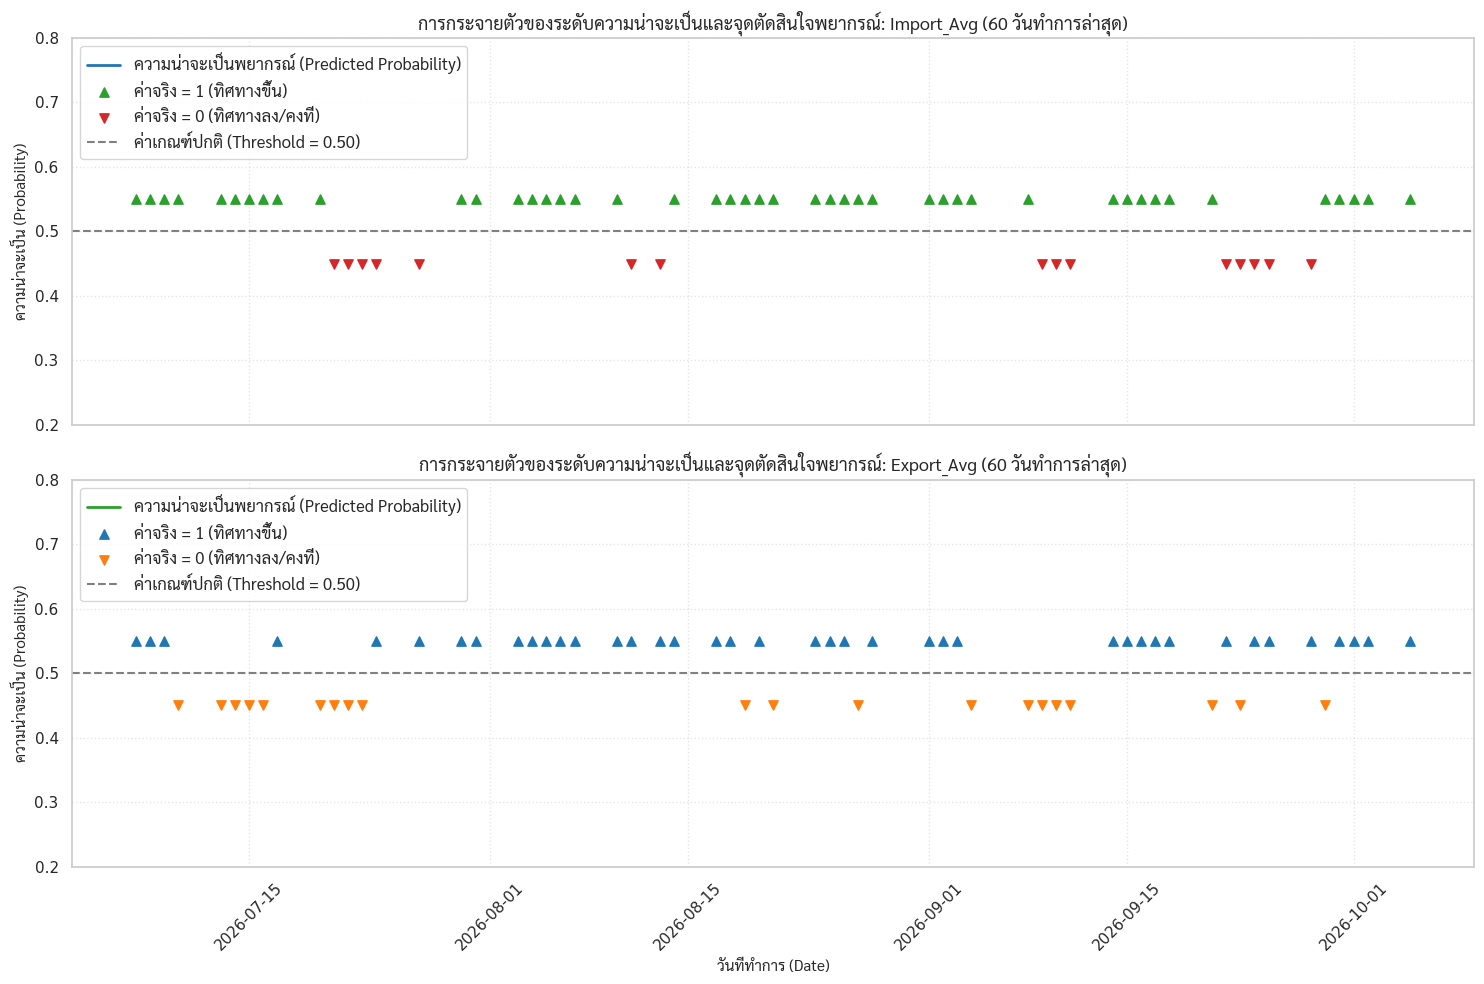


=== [ตารางวิเคราะห์การปรับเปลี่ยนค่าเกณฑ์ตัดสินใจพยากรณ์ (Threshold Sensitivity Analysis) บน Test Set] ===

* ตัวแปรเป้าหมาย: Import_Avg


,ตัวแปรเป้าหมาย,Threshold,Accuracy,Precision,Recall,F1-Score,สัดส่วนคำพยากรณ์คลาส 1
0,Import_Avg,0.50,0.550,0.675127,0.534137,0.596413,49.25%
1,Import_Avg,0.52,0.545,0.673575,0.522088,0.588235,48.25%
2,Import_Avg,0.55,0.550,0.690608,0.502008,0.581395,45.25%
3,Import_Avg,0.58,0.540,0.692308,0.469880,0.559809,42.25%
4,Import_Avg,0.60,0.540,0.696970,0.461847,0.555556,41.25%



* ตัวแปรเป้าหมาย: Export_Avg


,ตัวแปรเป้าหมาย,Threshold,Accuracy,Precision,Recall,F1-Score,สัดส่วนคำพยากรณ์คลาส 1
0,Export_Avg,0.50,0.6200,0.623729,0.817778,0.707692,73.75%
1,Export_Avg,0.52,0.6100,0.622776,0.777778,0.691700,70.25%
2,Export_Avg,0.55,0.6025,0.628906,0.715556,0.669439,64.00%
3,Export_Avg,0.58,0.5850,0.621399,0.671111,0.645299,60.75%
4,Export_Avg,0.60,0.5750,0.618026,0.640000,0.628821,58.25%


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. ตั้งค่าฟอนต์ภาษาไทยสำหรับการพล็อตกราฟ
thai_font = fm.FontProperties(fname='./Sarabun-Regular.ttf')
plt.rcParams['font.family'] = 'Sarabun'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid")

# 2. ตรวจสอบการพยากรณ์และคำนวณระดับความน่าจะเป็น (predict_proba[:, 1]) บนชุดข้อมูลทดสอบ
# ดึงออบเจกต์โมเดลที่ดีที่สุด (Logistic Regression ในรูป Pipeline)
best_lr_import = best_models_per_target['Import_Avg'][1]
best_lr_export = best_models_per_target['Export_Avg'][1]

# คำนวณความน่าจะเป็นของคลาส 1 (ทิศทางราคาเป็นบวก)
probs_import = best_lr_import.predict_proba(X_test)[:, 1]
probs_export = best_lr_export.predict_proba(X_test)[:, 1]
y_true_import = Y_test['Import_Avg'].values
y_true_export = Y_test['Export_Avg'].values

# เตรียมโครงสร้าง DataFrame หลักสำหรับการวิเคราะห์ข้อมูล
df_prob_analysis = pd.DataFrame({
    'Date': pd.to_datetime(test_dates),
    'True_Import': y_true_import,
    'Prob_Import': probs_import,
    'True_Export': y_true_export,
    'Prob_Export': probs_export
}).sort_values('Date').reset_index(drop=True)

# 3. จัดทำตารางสรุปสถิติเปรียบเทียบสัดส่วนและการแกว่งตัว
def get_stats_summary(df, cols, label_prefix):
    summary_rows = []
    for c_name, target in [('Prob_Import', 'Import_Avg'), ('Prob_Export', 'Export_Avg')]:
        series_all = df[c_name]
        series_60 = df[c_name].tail(60)

        summary_rows.append({
            'ตัวแปรเป้าหมาย': target,
            'ช่วงข้อมูล': f'ภาพรวม {label_prefix}',
            'Minimum': f'{series_all.min():.4f}',
            'Median': f'{series_all.median():.4f}',
            'Mean (ค่าเฉลี่ย)': f'{series_all.mean():.4f}',
            'Maximum': f'{series_all.max():.4f}',
            'สัดส่วนที่ทายเป็น 1 (> 0.50)': f'{(series_all > 0.50).mean():.2%}'
        })
        summary_rows.append({
            'ตัวแปรเป้าหมาย': target,
            'ช่วงข้อมูล': '60 วันทำการล่าสุด',
            'Minimum': f'{series_60.min():.4f}',
            'Median': f'{series_60.median():.4f}',
            'Mean (ค่าเฉลี่ย)': f'{series_60.mean():.4f}',
            'Maximum': f'{series_60.max():.4f}',
            'สัดส่วนที่ทายเป็น 1 (> 0.50)': f'{(series_60 > 0.50).mean():.2%}'
        })
    return pd.DataFrame(summary_rows)

df_stats_summary = get_stats_summary(df_prob_analysis, ['Prob_Import', 'Prob_Export'], f'Test Set ({len(df_prob_analysis)} วัน)')
print("=== [ตารางสรุปข้อมูลสถิติเชิงพรรณนาและการแจกแจงของค่าความน่าจะเป็น] ===")
display(df_stats_summary)

# =========================================================================
# ส่วนที่ 1: พล็อตกราฟค่าความน่าจะเป็นเทียบกับเส้นเกณฑ์ 0.50 (60 วันล่าสุด)
# =========================================================================
df_last_60 = df_prob_analysis.tail(60).reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

# กราฟย่อยที่ 1: Import_Avg
ax1.plot(df_last_60['Date'], df_last_60['Prob_Import'], color='#1f77b4', label='ความน่าจะเป็นพยากรณ์ (Predicted Probability)', linewidth=2)
# จุดแสดงคลาสจริง
ax1.scatter(df_last_60[df_last_60['True_Import'] == 1]['Date'], [0.55] * len(df_last_60[df_last_60['True_Import'] == 1]), color='#2ca02c', marker='^', s=45, label='ค่าจริง = 1 (ทิศทางขึ้น)', zorder=5)
ax1.scatter(df_last_60[df_last_60['True_Import'] == 0]['Date'], [0.45] * len(df_last_60[df_last_60['True_Import'] == 0]), color='#d62728', marker='v', s=45, label='ค่าจริง = 0 (ทิศทางลง/คงที่)', zorder=5)
ax1.axhline(0.50, color='grey', linestyle='--', linewidth=1.5, label='ค่าเกณฑ์ปกติ (Threshold = 0.50)')
ax1.set_title('การกระจายตัวของระดับความน่าจะเป็นและจุดตัดสินใจพยากรณ์: Import_Avg (60 วันทำการล่าสุด)', fontproperties=thai_font, fontsize=13, fontweight='bold')
ax1.set_ylabel('ความน่าจะเป็น (Probability)', fontproperties=thai_font, fontsize=11)
ax1.set_ylim(0.20, 0.80)
ax1.legend(prop=thai_font, loc='upper left')
ax1.grid(True, linestyle=':', alpha=0.5)

# กราฟย่อยที่ 2: Export_Avg
ax2.plot(df_last_60['Date'], df_last_60['Prob_Export'], color='#2ca02c', label='ความน่าจะเป็นพยากรณ์ (Predicted Probability)', linewidth=2)
# จุดแสดงคลาสจริง
ax2.scatter(df_last_60[df_last_60['True_Export'] == 1]['Date'], [0.55] * len(df_last_60[df_last_60['True_Export'] == 1]), color='#1f77b4', marker='^', s=45, label='ค่าจริง = 1 (ทิศทางขึ้น)', zorder=5)
ax2.scatter(df_last_60[df_last_60['True_Export'] == 0]['Date'], [0.45] * len(df_last_60[df_last_60['True_Export'] == 0]), color='#ff7f0e', marker='v', s=45, label='ค่าจริง = 0 (ทิศทางลง/คงที่)', zorder=5)
ax2.axhline(0.50, color='grey', linestyle='--', linewidth=1.5, label='ค่าเกณฑ์ปกติ (Threshold = 0.50)')
ax2.set_title('การกระจายตัวของระดับความน่าจะเป็นและจุดตัดสินใจพยากรณ์: Export_Avg (60 วันทำการล่าสุด)', fontproperties=thai_font, fontsize=13, fontweight='bold')
ax2.set_xlabel('วันที่ทำการ (Date)', fontproperties=thai_font, fontsize=11)
ax2.set_ylabel('ความน่าจะเป็น (Probability)', fontproperties=thai_font, fontsize=11)
ax2.set_ylim(0.20, 0.80)
ax2.legend(prop=thai_font, loc='upper left')
ax2.grid(True, linestyle=':', alpha=0.5)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# =========================================================================
# ส่วนที่ 2: การทดสอบเปรียบเทียบค่าเกณฑ์พยากรณ์ (Threshold Sensitivity Analysis)
# =========================================================================
thresholds = [0.50, 0.52, 0.55, 0.58, 0.60]
treshold_tuning_results = []

for target_name, true_vals, prob_vals in [('Import_Avg', y_true_import, probs_import), ('Export_Avg', y_true_export, probs_export)]:
    for th in thresholds:
        # หาก Probability มากกว่า Threshold ให้ทาย 1 มิฉะนั้นทาย 0
        tuned_preds = np.where(prob_vals > th, 1, 0)

        acc = accuracy_score(true_vals, tuned_preds)
        prec = precision_score(true_vals, tuned_preds, zero_division=0)
        rec = recall_score(true_vals, tuned_preds, zero_division=0)
        f1 = f1_score(true_vals, tuned_preds, zero_division=0)
        class_1_ratio = np.mean(tuned_preds == 1)

        treshold_tuning_results.append({
            'ตัวแปรเป้าหมาย': target_name,
            'Threshold': f'{th:.2f}',
            'Accuracy': acc,
            'Precision': prec,
            'Recall': rec,
            'F1-Score': f1,
            'สัดส่วนคำพยากรณ์คลาส 1': f'{class_1_ratio:.2%}'
        })

df_tuning_summary = pd.DataFrame(treshold_tuning_results)
print("\n=== [ตารางวิเคราะห์การปรับเปลี่ยนค่าเกณฑ์ตัดสินใจพยากรณ์ (Threshold Sensitivity Analysis) บน Test Set] ===")
for target in ['Import_Avg', 'Export_Avg']:
    print(f"\n* ตัวแปรเป้าหมาย: {target}")
    display(df_tuning_summary[df_tuning_summary['ตัวแปรเป้าหมาย'] == target].reset_index(drop=True))

### 4.7 การวิเคราะห์ประสิทธิภาพและการแจกแจงความน่าจะเป็นแบบรายปี (Yearly Performance & Probability Breakdown on Test Set)

เพื่อทำความเข้าใจการเปลี่ยนแปลงในเชิงพฤติกรรมความแม่นยำ (Model Robustness & Temporal Drift) ของตัวแบบที่ดีที่สุดสำหรับ `Import_Avg` และ `Export_Avg` เซลล์นี้จะทำหน้าที่แบ่งหน้าต่างข้อมูลการประเมินออกเป็นรายปีตามปฏิทินจริงในชุด Test Set (2024, 2025, 2026) โดย:
1. วิเคราะห์สัดส่วนคลาสจริงเทียบกับสัดส่วนพยากรณ์รายปี
2. สรุปมาตรวัดชี้วัดประสิทธิภาพ (ROC-AUC, Accuracy, Precision, Recall, F1-Score และค่ากลาง Probabilities) รายปี
3. แสดงแผนภูมิแท่งเปรียบเทียบประสิทธิผลรายปี

=== [ตารางวิเคราะห์สรุปผลประสิทธิภาพและการแจกแจงแบบรายปีบน Test Set] ===

* ตัวแปรเป้าหมาย: Import_Avg


,ตัวแปรเป้าหมาย,ปี ค.ศ.,จำนวนแถว (วัน),สัดส่วนคลาสจริง 1 (Actual Up),สัดส่วนพยากรณ์ 1 (Pred Up),ROC-AUC,Accuracy,Precision,Recall,F1-Score,Mean Prob,Median Prob
0,Import_Avg,2024,3,0.00%,0.00%,0.5000,1.0000,0.0000,0.0000,0.0000,0.3461,0.3690
1,Import_Avg,2025,224,56.70%,12.05%,0.5677,0.4375,0.5185,0.1102,0.1818,0.3778,0.3637
2,Import_Avg,2026,173,70.52%,98.27%,0.4182,0.6879,0.7000,0.9754,0.8151,0.8708,0.9561



* ตัวแปรเป้าหมาย: Export_Avg


,ตัวแปรเป้าหมาย,ปี ค.ศ.,จำนวนแถว (วัน),สัดส่วนคลาสจริง 1 (Actual Up),สัดส่วนพยากรณ์ 1 (Pred Up),ROC-AUC,Accuracy,Precision,Recall,F1-Score,Mean Prob,Median Prob
0,Export_Avg,2024,3,66.67%,33.33%,1.0000,0.6667,1.0000,0.5000,0.6667,0.4512,0.4454
1,Export_Avg,2025,224,46.43%,54.02%,0.5329,0.5670,0.5289,0.6154,0.5689,0.5192,0.5165
2,Export_Avg,2026,173,68.79%,100.00%,0.4169,0.6879,0.6879,1.0000,0.8151,0.9352,0.9837


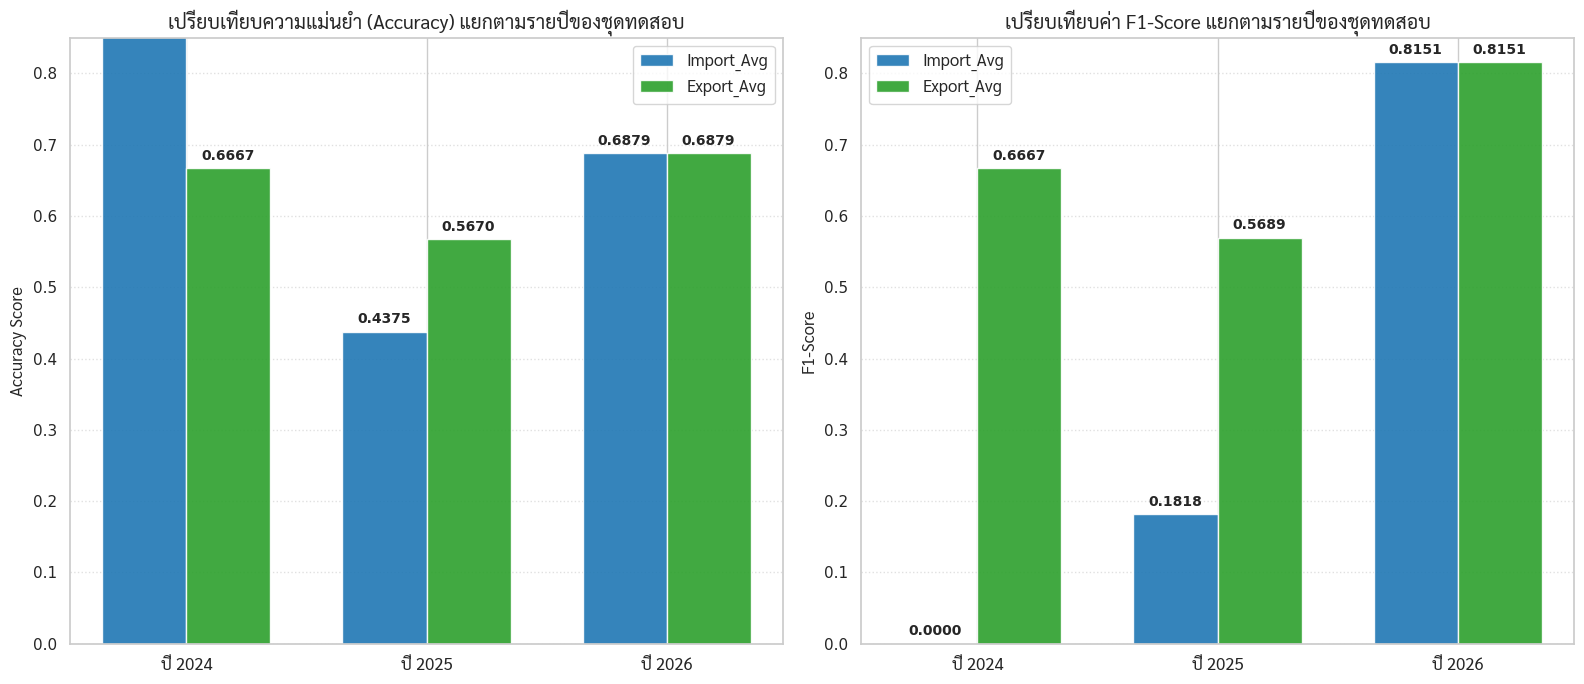

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score

# 1. ตั้งค่าฟอนต์ภาษาไทยสำหรับ Matplotlib และ Seaborn
thai_font = fm.FontProperties(fname='./Sarabun-Regular.ttf')
plt.rcParams['font.family'] = 'Sarabun'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid")

# 2. เตรียมข้อมูลทำนาย (predict_proba) และดึงข้อมูลปี (Year) จากชุดทดสอบ
best_lr_import = best_models_per_target['Import_Avg'][1]
best_lr_export = best_models_per_target['Export_Avg'][1]

probs_import = best_lr_import.predict_proba(X_test)[:, 1]
probs_export = best_lr_export.predict_proba(X_test)[:, 1]

y_true_import = Y_test['Import_Avg'].values
y_true_export = Y_test['Export_Avg'].values

# สร้าง DataFrame สรุปรวมบนชุดทดสอบพร้อมระบุปี
df_yearly_base = pd.DataFrame({
    'Date': pd.to_datetime(test_dates),
    'Year': pd.to_datetime(test_dates).dt.year,
    'True_Import': y_true_import,
    'Pred_Import': best_lr_import.predict(X_test),
    'Prob_Import': probs_import,
    'True_Export': y_true_export,
    'Pred_Export': best_lr_export.predict(X_test),
    'Prob_Export': probs_export
})

unique_years = sorted(df_yearly_base['Year'].unique())

# 3. คำนวณสถิติและประสิทธิภาพรายปีแยกตามแต่ละ Target
yearly_metrics_rows = []

for target, true_col, pred_col, prob_col in [
    ('Import_Avg', 'True_Import', 'Pred_Import', 'Prob_Import'),
    ('Export_Avg', 'True_Export', 'Pred_Export', 'Prob_Export')
]:
    for year in unique_years:
        df_sub = df_yearly_base[df_yearly_base['Year'] == year]
        n_samples = len(df_sub)
        if n_samples == 0:
            continue

        y_true = df_sub[true_col].values
        y_pred = df_sub[pred_col].values
        y_prob = df_sub[prob_col].values

        # คำนวณคะแนนประสิทธิภาพ
        # กรณีสัดส่วนคลาสจริงมีเพียงคลาสเดียว จะไม่สามารถหา ROC-AUC ได้ จึงกำหนดเป็น 0.50 หรือ NaN
        if len(np.unique(y_true)) > 1:
            auc = roc_auc_score(y_true, y_prob)
        else:
            auc = 0.50

        acc = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred, zero_division=0)
        rec = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred, zero_division=0)

        yearly_metrics_rows.append({
            'ตัวแปรเป้าหมาย': target,
            'ปี ค.ศ.': year,
            'จำนวนแถว (วัน)': n_samples,
            'สัดส่วนคลาสจริง 1 (Actual Up)': f'{np.mean(y_true == 1):.2%}',
            'สัดส่วนพยากรณ์ 1 (Pred Up)': f'{np.mean(y_pred == 1):.2%}',
            'ROC-AUC': round(auc, 4),
            'Accuracy': round(acc, 4),
            'Precision': round(prec, 4),
            'Recall': round(rec, 4),
            'F1-Score': round(f1, 4),
            'Mean Prob': round(np.mean(y_prob), 4),
            'Median Prob': round(np.median(y_prob), 4)
        })

df_yearly_summary = pd.DataFrame(yearly_metrics_rows)

print("=== [ตารางวิเคราะห์สรุปผลประสิทธิภาพและการแจกแจงแบบรายปีบน Test Set] ===")
for target in ['Import_Avg', 'Export_Avg']:
    print(f"\n* ตัวแปรเป้าหมาย: {target}")
    display(df_yearly_summary[df_yearly_summary['ตัวแปรเป้าหมาย'] == target].reset_index(drop=True))

# =========================================================================
# 4. พล็อตกราฟเปรียบเทียบผลประสิทธิภาพรายปี (Accuracy & F1-Score)
# =========================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# เตรียมข้อมูลเฉพาะสำหรับการพล็อตกราฟ
x = np.arange(len(unique_years))
width = 0.35

# กราฟที่ 1: เปรียบเทียบ Accuracy รายปี
import_accs = df_yearly_summary[df_yearly_summary['ตัวแปรเป้าหมาย'] == 'Import_Avg']['Accuracy'].values
export_accs = df_yearly_summary[df_yearly_summary['ตัวแปรเป้าหมาย'] == 'Export_Avg']['Accuracy'].values

rects1 = ax1.bar(x - width/2, import_accs, width, label='Import_Avg', color='#1f77b4', alpha=0.9)
rects2 = ax1.bar(x + width/2, export_accs, width, label='Export_Avg', color='#2ca02c', alpha=0.9)

ax1.set_title('เปรียบเทียบความแม่นยำ (Accuracy) แยกตามรายปีของชุดทดสอบ', fontproperties=thai_font, fontsize=14, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels([f'ปี {yr}' for yr in unique_years], fontproperties=thai_font, fontsize=12)
ax1.set_ylabel('Accuracy Score', fontproperties=thai_font, fontsize=12)
ax1.set_ylim(0.0, 0.85)
ax1.legend(prop=thai_font)
ax1.grid(axis='y', linestyle=':', alpha=0.6)

# กราฟที่ 2: เปรียบเทียบ F1-Score รายปี
import_f1s = df_yearly_summary[df_yearly_summary['ตัวแปรเป้าหมาย'] == 'Import_Avg']['F1-Score'].values
export_f1s = df_yearly_summary[df_yearly_summary['ตัวแปรเป้าหมาย'] == 'Export_Avg']['F1-Score'].values

rects3 = ax2.bar(x - width/2, import_f1s, width, label='Import_Avg', color='#1f77b4', alpha=0.9)
rects4 = ax2.bar(x + width/2, export_f1s, width, label='Export_Avg', color='#2ca02c', alpha=0.9)

ax2.set_title('เปรียบเทียบค่า F1-Score แยกตามรายปีของชุดทดสอบ', fontproperties=thai_font, fontsize=14, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels([f'ปี {yr}' for yr in unique_years], fontproperties=thai_font, fontsize=12)
ax2.set_ylabel('F1-Score', fontproperties=thai_font, fontsize=12)
ax2.set_ylim(0.0, 0.85)
ax2.legend(prop=thai_font)
ax2.grid(axis='y', linestyle=':', alpha=0.6)

# ฟังก์ชันเสริมช่วยใส่ตัวเลขกำกับแท่งกราฟ
def set_bar_labels(rects, ax):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='semibold')

set_bar_labels(rects1, ax1)
set_bar_labels(rects2, ax1)
set_bar_labels(rects3, ax2)
set_bar_labels(rects4, ax2)

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import matplotlib.font_manager as fm

# 1. ตั้งค่าฟอนต์ภาษาไทยสำหรับการพล็อตกราฟ
thai_font = fm.FontProperties(fname='./Sarabun-Regular.ttf')
plt.rcParams['font.family'] = 'Sarabun'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid")

# 2. ดึงข้อมูล 421 วันทำการล่าสุุด
df_plot_421 = df_forecast_421.copy()
df_plot_421['Date'] = pd.to_datetime(df_plot_421['Date'])

# 3. เริ่มพล็อตกราฟเปรียบเทียบระดับความน่าจะเป็นรายวัน
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 12), sharex=True)

# Subplot 1: Import_Avg
ax1.plot(df_plot_421['Date'], df_plot_421['Prob_Import'], color='#1f77b4', label='ความน่าจะเป็นพยากรณ์ (Predicted Probability)', linewidth=1.5)
ax1.scatter(df_plot_421[df_plot_421['Actual_Import'] == 1]['Date'], [0.55] * len(df_plot_421[df_plot_421['Actual_Import'] == 1]),
            color='#2ca02c', marker='^', s=20, alpha=0.6, label='ค่าจริง = 1 (ทิศทางขึ้น)', zorder=5)
ax1.scatter(df_plot_421[df_plot_421['Actual_Import'] == 0]['Date'], [0.45] * len(df_plot_421[df_plot_421['Actual_Import'] == 0]),
            color='#d62728', marker='v', s=20, alpha=0.6, label='ค่าจริง = 0 (ทิศทางลง/คงที่)', zorder=5)
ax1.axhline(0.50, color='grey', linestyle='--', linewidth=1.5, label='ค่าเกณฑ์ปกติ (Threshold = 0.50)')
ax1.set_title('การกระจายตัวของระดับความน่าจะเป็นและจุดพยากรณ์จริง: Import_Avg (ตลอด 421 วันทำการใน Test Set)', fontproperties=thai_font, fontsize=14, fontweight='bold')
ax1.set_ylabel('ความน่าจะเป็น (Probability)', fontproperties=thai_font, fontsize=11)
ax1.set_ylim(0.15, 0.85)
ax1.legend(prop=thai_font, loc='upper left')
ax1.grid(True, linestyle=':', alpha=0.5)

# Subplot 2: Export_Avg
ax2.plot(df_plot_421['Date'], df_plot_421['Prob_Export'], color='#2ca02c', label='ความน่าจะเป็นพยากรณ์ (Predicted Probability)', linewidth=1.5)
ax2.scatter(df_plot_421[df_plot_421['Actual_Export'] == 1]['Date'], [0.55] * len(df_plot_421[df_plot_421['Actual_Export'] == 1]),
            color='#1f77b4', marker='^', s=20, alpha=0.6, label='ค่าจริง = 1 (ทิศทางขึ้น)', zorder=5)
ax2.scatter(df_plot_421[df_plot_421['Actual_Export'] == 0]['Date'], [0.45] * len(df_plot_421[df_plot_421['Actual_Export'] == 0]),
            color='#ff7f0e', marker='v', s=20, alpha=0.6, label='ค่าจริง = 0 (ทิศทางลง/คงที่)', zorder=5)
ax2.axhline(0.50, color='grey', linestyle='--', linewidth=1.5, label='ค่าเกณฑ์ปกติ (Threshold = 0.50)')
ax2.set_title('การกระจายตัวของระดับความน่าจะเป็นและจุดพยากรณ์จริง: Export_Avg (ตลอด 421 วันทำการใน Test Set)', fontproperties=thai_font, fontsize=14, fontweight='bold')
ax2.set_xlabel('วันที่ทำการ (Date)', fontproperties=thai_font, fontsize=11)
ax2.set_ylabel('ความน่าจะเป็น (Probability)', fontproperties=thai_font, fontsize=11)
ax2.set_ylim(0.15, 0.85)
ax2.legend(prop=thai_font, loc='upper left')
ax2.grid(True, linestyle=':', alpha=0.5)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

NameError: name 'df_forecast_421' is not defined